# Pima Indians (en español) – Notebook

Objetivos:
- Cargar la base con variables en español
- Detectar valores nulos e inválidos (0 encubiertos)
- Imputar con mediana
- Graficar la presencia de Diabetes (DBT o dbt) en porcentajes
- Intervalo de confianza de niveles de glucosa por diagnóstico (dbt)
- Regresión lineal: glucosa ~ BMI + edad
- Extender modelo agregando antecedentes (anteced_dbt)
- Luego hacemos un modelo logístico, es decir cambiamos la variable    respuesta a tener o no DBT
- Verificamos si son significativas las variables incluidas y finalmente calculamos los OR o cocientes de chance, que me indican si promueven o protegen esas variables para tener DBT

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

plt.rcParams['figure.figsize'] = (7,4)

## 1. Carga de datos (dataset original + renombrado a español)

In [2]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'

columnas = [
    'num_embarazos', 'glucosa', 'presion_sist', 'pliegue_tricip',
    'insulina', 'bmi', 'anteced_dbt', 'edad', 'dbt'
]

df = pd.read_csv(url, names=columnas)
df.head()

,num_embarazos,glucosa,presion_sist,pliegue_tricip,insulina,bmi,anteced_dbt,edad,dbt
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Detección de valores nulos

In [5]:
df.isnull().sum()

,0
num_embarazos,0
glucosa,0
presion_sist,0
pliegue_tricip,0
insulina,0
bmi,0
anteced_dbt,0
edad,0
dbt,0


## 3. Tratamiento de valores 0 inválidos

En este dataset, varias variables fisiológicas pueden traer 0 como valor faltante encubierto.

In [6]:
cols_con_ceros_invalidos = ['glucosa', 'presion_sist', 'pliegue_tricip', 'insulina', 'bmi']

for col in cols_con_ceros_invalidos:
    print(f"{col}: {(df[col] == 0).sum()} valores en 0")

glucosa: 5 valores en 0
presion_sist: 35 valores en 0
pliegue_tricip: 227 valores en 0
insulina: 374 valores en 0
bmi: 11 valores en 0


In [7]:
df_imputado = df.copy()
df_imputado[cols_con_ceros_invalidos] = df_imputado[cols_con_ceros_invalidos].replace(0, np.nan)

for col in cols_con_ceros_invalidos:
    df_imputado[col] = df_imputado[col].fillna(df_imputado[col].median())

df_imputado.isnull().sum()

,0
num_embarazos,0
glucosa,0
presion_sist,0
pliegue_tricip,0
insulina,0
bmi,0
anteced_dbt,0
edad,0
dbt,0


## 4. Diagnóstico en porcentajes

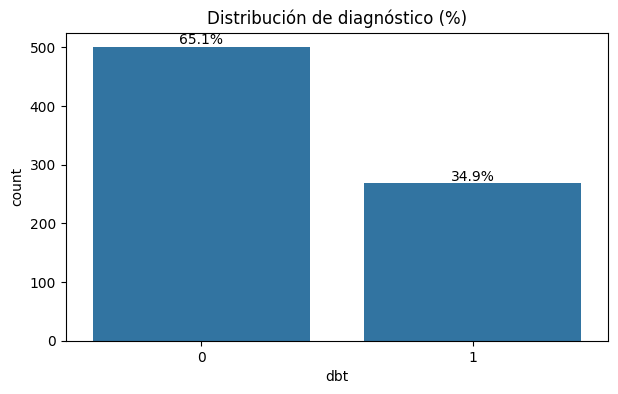

In [8]:
plt.figure()
ax = sns.countplot(data=df_imputado, x='dbt')

total = len(df_imputado)

for p in ax.patches:
    height = p.get_height()
    porcentaje = 100 * height / total
    ax.annotate(f"{porcentaje:.1f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom')

plt.title('Distribución de diagnóstico (%)')
plt.show()

## 5. Intervalo de confianza de glucosa por diagnóstico

In [9]:
def intervalo_confianza(data, confianza=0.95):
    n = len(data)
    media = np.mean(data)
    error_std = stats.sem(data)
    h = error_std * stats.t.ppf((1 + confianza) / 2, n - 1)
    return media, media - h, media + h

resultados = {}

for dbt, grupo in df_imputado.groupby('dbt'):
    media, li, ls = intervalo_confianza(grupo['glucosa'])
    resultados[dbt] = (media, li, ls)

resultados

{0: (np.float64(110.682),
  np.float64(108.51109267890268),
  np.float64(112.85290732109732)),
 1: (np.float64(142.13059701492537),
  np.float64(138.57438194116807),
  np.float64(145.68681208868267))}

In [10]:
print(f"Nivel de Confianza (NC): {0.95*100:.0f}%")
print("---------------------------------------------------")

for dbt, (media, li, ls) in resultados.items():
    diagnostico = "Diabético" if dbt == 1 else "No Diabético"
    print(f"Diagnóstico: {diagnostico}")
    print(f"  Media de Glucosa: {media:.2f}")
    print(f"  Límite Inferior (LI): {li:.2f}")
    print(f"  Límite Superior (LS): {ls:.2f}")
    print("---------------------------------------------------")

Nivel de Confianza (NC): 95%
---------------------------------------------------
Diagnóstico: No Diabético
  Media de Glucosa: 110.68
  Límite Inferior (LI): 108.51
  Límite Superior (LS): 112.85
---------------------------------------------------
Diagnóstico: Diabético
  Media de Glucosa: 142.13
  Límite Inferior (LI): 138.57
  Límite Superior (LS): 145.69
---------------------------------------------------


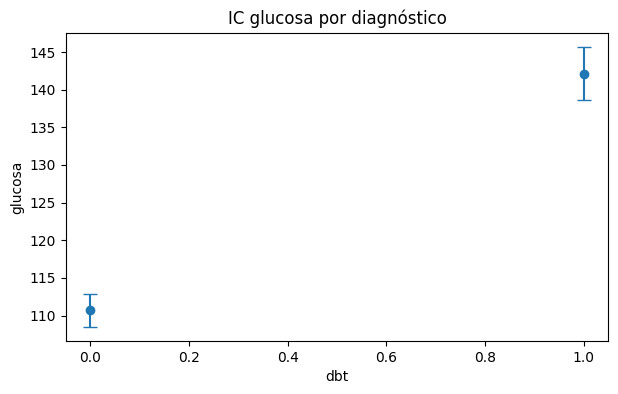

In [11]:
grupos, medias, li_list, ls_list = [], [], [], []

for g, (media, li, ls) in resultados.items():
    grupos.append(g)
    medias.append(media)
    li_list.append(media - li)
    ls_list.append(ls - media)

plt.errorbar(grupos, medias, yerr=[li_list, ls_list], fmt='o', capsize=5)
plt.title('IC glucosa por diagnóstico')
plt.xlabel('dbt')
plt.ylabel('glucosa')
plt.show()

## 6. Regresión lineal: glucosa ~ BMI + edad

In [12]:
X1 = df_imputado[['bmi', 'edad']]
y = df_imputado['glucosa']

X1 = sm.add_constant(X1)
modelo1 = sm.OLS(y, X1).fit()

print(modelo1.summary())

                            OLS Regression Results                            
Dep. Variable:                glucosa   R-squared:                       0.122
Model:                            OLS   Adj. R-squared:                  0.119
Method:                 Least Squares   F-statistic:                     52.92
Date:                Tue, 14 Apr 2026   Prob (F-statistic):           2.97e-22
Time:                        20:38:44   Log-Likelihood:                -3662.7
No. Observations:                 768   AIC:                             7331.
Df Residuals:                     765   BIC:                             7345.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         66.9484      5.707     11.732      0.0

## 7. Regresión lineal: agregando antecedentes

In [13]:
X2 = df_imputado[['bmi', 'edad', 'anteced_dbt']]
X2 = sm.add_constant(X2)

modelo2 = sm.OLS(y, X2).fit()

print(modelo2.summary())

                            OLS Regression Results                            
Dep. Variable:                glucosa   R-squared:                       0.131
Model:                            OLS   Adj. R-squared:                  0.127
Method:                 Least Squares   F-statistic:                     38.27
Date:                Tue, 14 Apr 2026   Prob (F-statistic):           4.81e-23
Time:                        20:39:18   Log-Likelihood:                -3658.7
No. Observations:                 768   AIC:                             7325.
Df Residuals:                     764   BIC:                             7344.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          65.1285      5.717     11.392      

In [14]:
resumen = modelo2.summary2().tables[1]
resumen["significativo"] = resumen["P>|t|"] < 0.05

print("Tabla de coeficientes:")
print(resumen)

Tabla de coeficientes:
                 Coef.  Std.Err.          t         P>|t|     [0.025  \
const        65.128453  5.717067  11.391934  7.051227e-28  53.905428   
bmi           0.928094  0.151168   6.139508  1.329721e-09   0.631341   
edad          0.668555  0.087377   7.651367  5.997530e-14   0.497027   
anteced_dbt   8.864517  3.137516   2.825330  4.846392e-03   2.705342   

                0.975]  significativo  
const        76.351478           True  
bmi           1.224847           True  
edad          0.840082           True  
anteced_dbt  15.023692           True  


In [16]:

#Importancia de los betas
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_std = scaler.fit_transform(df_imputado[["bmi", "edad", "anteced_dbt"]])
y_std = (df_imputado["glucosa"] - df_imputado["glucosa"].mean()) / df_imputado["glucosa"].std()

X_std = sm.add_constant(X_std)

modelo_std = sm.OLS(y_std, X_std).fit()

betas = modelo_std.params[1:]

import pandas as pd
import numpy as np

importancia = pd.DataFrame({
    "variable": ["bmi", "edad", "anteced_dbt"],
    "beta_estandarizado": betas
})

importancia["abs_beta"] = np.abs(importancia["beta_estandarizado"])
importancia = importancia.sort_values(by="abs_beta", ascending=False)

print("Importancia de variables:")
print(importancia)

Importancia de variables:
       variable  beta_estandarizado  abs_beta
x2         edad            0.258137  0.258137
x1          bmi            0.209495  0.209495
x3  anteced_dbt            0.096430  0.096430


Ecuación del modelo lineal


In [17]:
coef = modelo2.params

ecuacion = f"glucosa = {coef['const']:.2f}"

for var in ["bmi", "edad", "anteced_dbt"]:
    ecuacion += f" + ({coef[var]:.2f} * {var})"

print("\nEcuación del modelo:")
print(ecuacion)


Ecuación del modelo:
glucosa = 65.13 + (0.93 * bmi) + (0.67 * edad) + (8.86 * anteced_dbt)


Regresión logística (diabetes)

In [18]:
X_log = df_imputado[["edad", "bmi", "glucosa"]]
y_log = df_imputado["dbt"]

X_log = sm.add_constant(X_log)

modelo_log = sm.Logit(y_log, X_log).fit()

print(modelo_log.summary())

Optimization terminated successfully.
         Current function value: 0.480373
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                    dbt   No. Observations:                  768
Model:                          Logit   Df Residuals:                      764
Method:                           MLE   Df Model:                            3
Date:                Tue, 14 Apr 2026   Pseudo R-squ.:                  0.2573
Time:                        20:53:06   Log-Likelihood:                -368.93
converged:                       True   LL-Null:                       -496.74
Covariance Type:            nonrobust   LLR p-value:                 3.961e-55
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -9.1153      0.708    -12.875      0.000     -10.503      -7.728
edad           0.0292      0.

Calculamos los OR

In [19]:
odds_ratios = np.exp(modelo_log.params)

print("\nOdds Ratios:")
print(odds_ratios)


Odds Ratios:
const      0.000110
edad       1.029627
bmi        1.096162
glucosa    1.036175
dtype: float64


Como los OR son mayores a 1, eso indica que aumenta la chance de tener diabetes y Cuanto???  para la Edad por cada año de aumento de edad aumenta la chance un 2% (OR: 1,02); para el BMI por cada unidad que aumenta el BMI aumenta un 9 % la chance de presentar dbt y por cada undad que aumenta la glucosa aumenta la chance de tener DBT un 3%


Modelo logístico (ecuación final)

In [20]:
coef_log = modelo_log.params

ecuacion_log = f"logit(p) = {coef_log['const']:.2f}"

for var in ["edad", "bmi", "glucosa"]:
    ecuacion_log += f" + ({coef_log[var]:.2f} * {var})"

print("\nModelo logístico:")
print(ecuacion_log)

print("\nDonde:")
print("p = probabilidad de diabetes")
print("logit(p) = log(p / (1 - p))")


Modelo logístico:
logit(p) = -9.12 + (0.03 * edad) + (0.09 * bmi) + (0.04 * glucosa)

Donde:
p = probabilidad de diabetes
logit(p) = log(p / (1 - p))


Predicción de ejemplo: Si viene una persona de la misma población donde se sacó la muestra para el estudio PIMA, se indaga la edad, su bmi y nivel de glucosa. Luego se reemplaza en la fórmula y nos da la predicción de si tiene o no DBT.

In [29]:
nuevo = pd.DataFrame({
    "const": [1],
    "edad": [50],
    "bmi": [30],
    "glucosa": [150]
})

prob = modelo_log.predict(nuevo)

print(f"\nProbabilidad estimada de diabetes: {prob.iloc[0]:.3f}")


Probabilidad estimada de diabetes: 0.606


In [27]:
print(ecuacion_log)
print("Donde:")
print("p = probabilidad de diabetes")
print("logit(p) = log(p / (1 - p))")

logit(p) = -9.12 + (0.03 * edad) + (0.09 * bmi) + (0.04 * glucosa)
Donde:
p = probabilidad de diabetes
logit(p) = log(p / (1 - p))


In [23]:
edad_ejemplo = nuevo['edad'].iloc[0]
bmi_ejemplo = nuevo['bmi'].iloc[0]
glucosa_ejemplo = nuevo['glucosa'].iloc[0]

ecuacion_con_ejemplo = f"logit(p) = {coef_log['const']:.2f} + ({coef_log['edad']:.2f} * {edad_ejemplo}) + ({coef_log['bmi']:.2f} * {bmi_ejemplo}) + ({coef_log['glucosa']:.2f} * {glucosa_ejemplo})"

print("\nModelo logístico con datos de ejemplo:")
print(ecuacion_con_ejemplo)

valor_logit_calculado = coef_log['const'] + (coef_log['edad'] * edad_ejemplo) + (coef_log['bmi'] * bmi_ejemplo) + (coef_log['glucosa'] * glucosa_ejemplo)
print(f"Valor calculado de logit(p): {valor_logit_calculado:.3f}")



Modelo logístico con datos de ejemplo:
logit(p) = -9.12 + (0.03 * 50) + (0.09 * 30) + (0.04 * 150)
Valor calculado de logit(p): 0.429


In [30]:
import numpy as np

# valores del paciente (podés cambiarlos)
edad = 50
bmi = 30
glucosa = 150

# coeficientes reales del modelo (SIN redondear)
coef = modelo_log.params

# cálculo del logit
logit = (
    coef["const"]
    + coef["edad"] * edad
    + coef["bmi"] * bmi
    + coef["glucosa"] * glucosa
)

# transformación logística → probabilidad
prob = 1 / (1 + np.exp(-logit))

# impresión clara
print("Modelo logístico (coeficientes reales):")
print(
    f"logit(p) = {coef['const']:.6f} + "
    f"({coef['edad']:.6f} * edad) + "
    f"({coef['bmi']:.6f} * bmi) + "
    f"({coef['glucosa']:.6f} * glucosa)"
)

print("\nPaciente evaluado:")
print(f"edad = {edad}, bmi = {bmi}, glucosa = {glucosa}")

print("\nResultados:")
print(f"logit(p) = {logit:.6f}")
print(f"probabilidad = {prob:.6f}")

Modelo logístico (coeficientes reales):
logit(p) = -9.115284 + (0.029196 * edad) + (0.091815 * bmi) + (0.035536 * glucosa)

Paciente evaluado:
edad = 50, bmi = 30, glucosa = 150

Resultados:
logit(p) = 0.429427
probabilidad = 0.605737


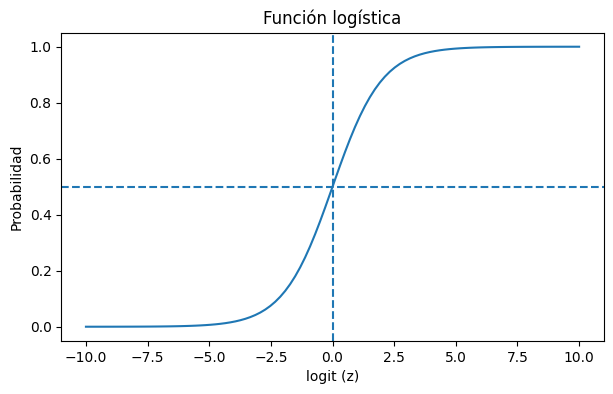

In [32]:
#Curva logística (concepto general)
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-10, 10, 100)
p = 1 / (1 + np.exp(-z))

plt.plot(z, p)
plt.axhline(0.5, linestyle='--')
plt.axvline(0, linestyle='--')

plt.title("Función logística")
plt.xlabel("logit (z)")
plt.ylabel("Probabilidad")

plt.show()

Text(0, 0.5, 'Probabilidad')

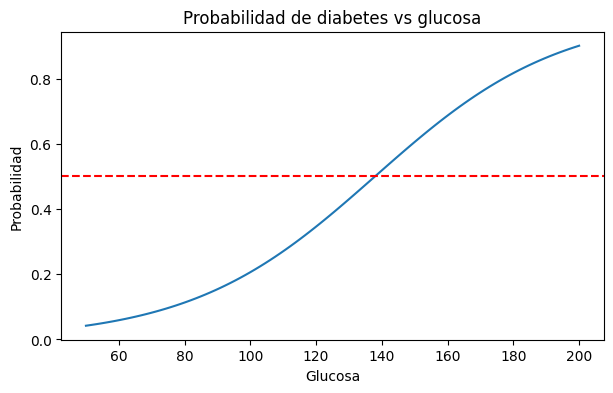

In [36]:
#Probabilidad de diabetes según glucosa (MUY potente)
glucosa_vals = np.linspace(50, 200, 100)

edad = 50
bmi = 30

coef = modelo_log.params

logits = (
    coef["const"]
    + coef["edad"] * edad
    + coef["bmi"] * bmi
    + coef["glucosa"] * glucosa_vals
)

probs = 1 / (1 + np.exp(-logits))

plt.plot(glucosa_vals, probs)
plt.axhline(0.5, linestyle='--', color='red')

plt.title("Probabilidad de diabetes vs glucosa")
plt.xlabel("Glucosa")
plt.ylabel("Probabilidad")



Al observar el gráfico previo vemos que el modelo empieza a predecir DBT cuando la probabilidad supera 0,5


In [38]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Probabilidades del modelo
probs = modelo_log.predict(X_log)

# thresholds a evaluar
thresholds = np.linspace(0, 1, 100)

resultados = []

for t in thresholds:
    y_pred = (probs >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_log, y_pred).ravel()

    sensibilidad = tp / (tp + fn)
    especificidad = tn / (tn + fp)

    diff = abs(sensibilidad - especificidad)

    resultados.append((t, sensibilidad, especificidad, diff))

# convertir a array
resultados = np.array(resultados)

# encontrar el mejor threshold (mínima diferencia)
best_idx = np.argmin(resultados[:, 3])

best_threshold = resultados[best_idx, 0]
best_sens = resultados[best_idx, 1]
best_spec = resultados[best_idx, 2]

print(f"Threshold óptimo: {best_threshold:.3f}")
print(f"Sensibilidad: {best_sens:.3f}")
print(f"Especificidad: {best_spec:.3f}")

Threshold óptimo: 0.323
Sensibilidad: 0.739
Especificidad: 0.728


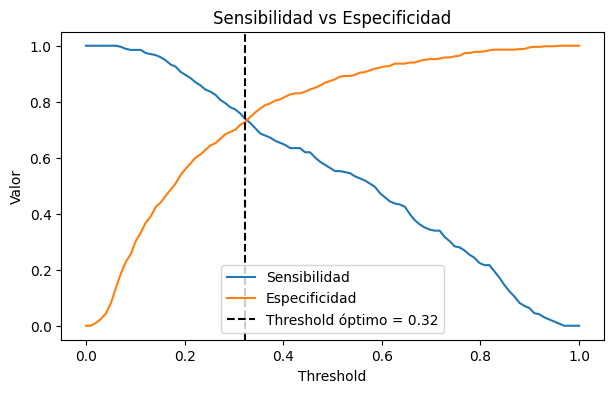

In [39]:
sens = resultados[:, 1]
spec = resultados[:, 2]

plt.plot(thresholds, sens, label="Sensibilidad")
plt.plot(thresholds, spec, label="Especificidad")

plt.axvline(best_threshold, linestyle="--", color="black", label=f"Threshold óptimo = {best_threshold:.2f}")

plt.xlabel("Threshold")
plt.ylabel("Valor")
plt.title("Sensibilidad vs Especificidad")

plt.legend()
plt.show()